### NHF Link-Based Routing with T-Route

#### Author: Tadd Bindas

This notebook demonstrates T-Route running on the NGWPC Hydrofabric (NHF) using link-based routing:

- Physical flowpaths are discretized into links (default 300m) for Muskingum-Cunge routing. Terminal virtual nexuses are positioned at their real geographic locations along each flowpath, defining segment boundaries.
- All virtual flowpaths (VFPs) receive flow-scaled output based on their area contribution ratios. 
- Output is reported at the flowpath (`fp_id`) level — each flowpath's Q/V/D comes from its most-downstream (outlet) link. VFP flow-scaled output is also included.

*NOTE*
This code assumes the following outputs have been created from a t-route run using the command:
`uv run python -m nwm_routing -V5 -f test_case.yaml` 
from the `test/nhf/conecuh_case` directory

In [1]:
# Imports
from pathlib import Path
from IPython.display import HTML, display

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import xarray as xr

import io
from PIL import Image as PILImage


In [2]:
# All functions
def create_flow_animation(
    ds: xr.Dataset,
    vfp: gpd.GeoDataFrame,
    divides: gpd.GeoDataFrame,
    fp: gpd.GeoDataFrame = None,
    subset_div_id: int = None,
    ref_fp: gpd.GeoDataFrame = None,
    time_step: int = 1,
    figsize: tuple = (12, 10),
    save_path: str = None,
    fps: int = 4,
    cmap: str = "Blues",
) -> None:
    """
    Create flow animation by re-plotting the GeoDataFrame each frame.
    
    Parameters
    ----------
    ds : xr.Dataset
        T-route output dataset with 'flow' variable and 'feature_id' coordinate.
        Feature IDs are fp_ids (flowpath-level) and VFP IDs.
    vfp : gpd.GeoDataFrame
        Virtual flowpaths with geometry and virtual_fp_id
    divides : gpd.GeoDataFrame
        Divide polygons for background
    fp : gpd.GeoDataFrame, optional
        Physical flowpaths with geometry, colored by routed fp_id flow
    subset_div_id : int, optional
        If provided, filter to only show flowpaths in this divide
    ref_fp : gpd.GeoDataFrame, optional
        Reference flowpaths for merging div_id to virtual flowpaths
    time_step : int
        Sample every nth timestep for faster rendering
    figsize : tuple
        Figure size
    save_path : str
        Path to save the GIF (required)
    fps : int
        Frames per second for the animation
    cmap : str
        Matplotlib colormap name
    """
    if save_path is None:
        raise ValueError("save_path is required")
    
    # Merge vfp with ref_fp if provided and subset_div_id requested
    if subset_div_id is not None and ref_fp is not None:
        vfp_merged = vfp.merge(
            ref_fp[["virtual_fp_id", "div_id"]],
            on="virtual_fp_id",
            how="left"
        )
        vfp_plot = vfp_merged[vfp_merged["div_id"] == subset_div_id].copy()
        divides_plot = divides[divides["div_id"] == subset_div_id]
        fp_plot = fp[fp["div_id"] == subset_div_id] if fp is not None else None
        title_suffix = f" (Divide {subset_div_id})"
    else:
        vfp_plot = vfp.copy()
        divides_plot = divides
        fp_plot = fp
        title_suffix = " (Full Domain)"
    
    # Get feature IDs that exist in both dataset and geodataframe
    ds_feature_ids = set(ds.feature_id.values)
    vfp_ids = set(vfp_plot["virtual_fp_id"].values)
    common_ids = list(ds_feature_ids & vfp_ids)
    
    if not common_ids:
        raise ValueError("No common feature IDs between dataset and geodataframe")
    
    vfp_plot = vfp_plot[vfp_plot["virtual_fp_id"].isin(common_ids)].copy()
    
    # fp_ids in output for physical flowpath coloring
    fp_ids_in_ds = set()
    if fp_plot is not None:
        fp_ids_in_ds = set(int(fid) for fid in fp_plot["fp_id"] if int(fid) in ds_feature_ids)
    
    # Sample timesteps
    times = ds.time.values[::time_step]
    n_frames = len(times)
    
    # Normalization from all flows (VFPs + fp_ids)
    all_flows = ds.sel(feature_id=common_ids).flow.values.ravel()
    if fp_ids_in_ds:
        fp_flows = ds.sel(feature_id=list(fp_ids_in_ds)).flow.values.ravel()
        all_flows = np.concatenate([all_flows, fp_flows])
    
    vmin = np.nanmin(all_flows)
    vmax = np.nanmax(all_flows)
    
    if vmax > 0 and vmax / max(vmin, 1e-6) > 100:
        norm = mcolors.LogNorm(vmin=max(vmin, 1e-6), vmax=vmax)
    else:
        norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    
    bounds = vfp_plot.total_bounds
    if fp_plot is not None and len(fp_plot) > 0:
        fp_bounds = fp_plot.total_bounds
        bounds = [
            min(bounds[0], fp_bounds[0]),
            min(bounds[1], fp_bounds[1]),
            max(bounds[2], fp_bounds[2]),
            max(bounds[3], fp_bounds[3]),
        ]
    
    frames = []
    
    print(f"Generating {n_frames} frames...")
    for i, t in enumerate(times):
        if i % 10 == 0:
            print(f"  Frame {i}/{n_frames}")
        
        fig, ax = plt.subplots(figsize=figsize)
        divides_plot.plot(ax=ax, color="lightgray", edgecolor="gray", alpha=0.5)
        
        flow_at_t = ds.sel(time=t).flow
        
        # Draw physical flowpaths colored by routed fp_id flow
        if fp_plot is not None and fp_ids_in_ds:
            fp_draw = fp_plot.copy()
            fp_draw["flow"] = fp_draw["fp_id"].map(
                lambda fid: float(flow_at_t.sel(feature_id=int(fid)).values)
                if int(fid) in ds_feature_ids
                else np.nan
            )
            fp_draw.plot(
                ax=ax,
                column="flow",
                cmap=cmap,
                norm=norm,
                linewidth=2.5,
                legend=False,
                missing_kwds={"color": "lightgray", "linewidth": 0.5, "alpha": 0.4},
            )
        elif fp_plot is not None:
            fp_plot.plot(ax=ax, color="lightsteelblue", linewidth=0.5, alpha=0.6)
        
        vfp_plot["flow"] = vfp_plot["virtual_fp_id"].map(
            lambda fid: float(flow_at_t.sel(feature_id=fid).values) 
            if fid in ds.feature_id.values else np.nan
        )
        
        vfp_plot.plot(
            ax=ax,
            column="flow",
            cmap=cmap,
            norm=norm,
            linewidth=1.5,
            legend=True,
            legend_kwds={"label": "Flow (m³/s)", "shrink": 0.6},
        )
        
        ax.set_xlim(bounds[0], bounds[2])
        ax.set_ylim(bounds[1], bounds[3])
        ax.set_title(f"Flow Animation{title_suffix}\nTime: {pd.Timestamp(t)}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
        buf.seek(0)
        frames.append(PILImage.open(buf).copy())
        buf.close()
        plt.close(fig)
    
    print(f"Saving GIF to {save_path}...")
    frames[0].save(
        save_path,
        save_all=True,
        append_images=frames[1:],
        duration=1000 // fps,
        loop=0
    )
    print("Done!")

In [3]:
from shapely.geometry import Point

def visualize_links_and_vfps(
    ds: xr.Dataset,
    fp: gpd.GeoDataFrame,
    vfp: gpd.GeoDataFrame,
    ref_fp: gpd.GeoDataFrame,
    divides: gpd.GeoDataFrame,
    links_df: pd.DataFrame,
    nodes_df: pd.DataFrame,
    vnex: gpd.GeoDataFrame,
    nexus_gdf: gpd.GeoDataFrame,
    sample_div_id: int,
    figsize: tuple = (16, 7),
    save_path: str = None,
):
    """
    Visualize the link vs VFP architecture for a given divide.
    
    Left panel: Map with physical flowpath (thick blue = discretized into links),
                all VFPs (thin dashed = flow-scaled), and node positions along
                the flowpath (triangles = terminal nexus, dots = internal nodes).
    Right panel: Double-y hydrograph — VFP flow-scaled flows on the left y-axis,
                routed discharge at the flowpath outlet (fp_id) on the right y-axis.
    """
    # Get flowpath for this divide
    fp_subset = fp[fp["div_id"] == sample_div_id]
    div_subset = divides[divides["div_id"] == sample_div_id]
    
    # Get VFPs for this divide via reference_flowpaths
    vfp_refs = ref_fp[
        (ref_fp["div_id"] == sample_div_id) & (ref_fp["virtual_fp_id"].notna())
    ]
    vfp_ids_in_div = set(vfp_refs["virtual_fp_id"].astype(int))
    vfp_subset = vfp[vfp["virtual_fp_id"].isin(vfp_ids_in_div)].copy()
    
    # Get links and nodes for this divide
    div_links = links_df[links_df["div_id"] == sample_div_id]
    n_links = len(div_links)
    fp_id = int(fp_subset.iloc[0]["fp_id"]) if len(fp_subset) > 0 else None
    div_nodes = nodes_df[nodes_df["fp_id"] == fp_id] if fp_id else pd.DataFrame()
    
    # Get VFP flows from dataset
    ds_fids = set(ds.feature_id.values)
    vfp_in_ds = vfp_subset[vfp_subset["virtual_fp_id"].isin(ds_fids)].copy()
    
    # Colors for VFPs
    n_vfps = len(vfp_in_ds)
    cmap_name = "tab20" if n_vfps <= 20 else "hsv"
    cmap = plt.colormaps[cmap_name]
    vfp_colors = {
        fid: cmap(i / max(n_vfps - 1, 1)) 
        for i, fid in enumerate(vfp_in_ds["virtual_fp_id"])
    }
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # ------------------------------------------------------------------
    # Left panel: Map with flowpath, VFPs, and node positions
    # ------------------------------------------------------------------
    div_subset.plot(ax=ax1, facecolor="none", edgecolor="gray")
    fp_subset.plot(ax=ax1, color="blue", linewidth=3, label=f"Flowpath ({n_links} links)")
    
    for _, row in vfp_in_ds.iterrows():
        fid = row["virtual_fp_id"]
        gpd.GeoDataFrame([row], crs=vfp_in_ds.crs).plot(
            ax=ax1, color=vfp_colors[fid], linewidth=1.5, linestyle="--"
        )
    
    # Compute and plot node positions along the flowpath
    if fp_id is not None and len(fp_subset) > 0 and not div_nodes.empty:
        fp_geom = fp_subset.iloc[0].geometry
        if fp_geom is not None:
            if fp_geom.geom_type == "MultiLineString":
                fp_geom = fp_geom.geoms[0]
            
            # Determine direction: downstream nexus near start or end?
            dn_nex_id = int(fp_subset.iloc[0]["dn_nex_id"])
            dn_nex_row = nexus_gdf[nexus_gdf["nex_id"] == dn_nex_id]
            if len(dn_nex_row) > 0 and dn_nex_row.iloc[0].geometry is not None:
                dn_pt = dn_nex_row.iloc[0].geometry
                d_start = dn_pt.distance(Point(fp_geom.coords[0]))
                d_end = dn_pt.distance(Point(fp_geom.coords[-1]))
                downstream_at_start = d_start < d_end
            else:
                downstream_at_start = True
            
            fp_len_m = fp_geom.length
            length_km = fp_subset.iloc[0]["length_km"]
            
            # Walk links downstream→upstream to get cumulative node distances
            # Build ordered link chain
            link_chain = []
            # Find the most-downstream link (dn_node_id == dn_nex_id)
            start_links = div_links[div_links["dn_node_id"] == dn_nex_id]
            if len(start_links) > 0:
                current = start_links.index[0]
                while current is not None:
                    link_chain.append(current)
                    up_node = div_links.loc[current, "up_node_id"]
                    if pd.isna(up_node):
                        break
                    up_node = int(up_node)
                    # Find the next link whose dn_node_id == up_node
                    next_links = div_links[div_links["dn_node_id"] == up_node]
                    current = next_links.index[0] if len(next_links) > 0 else None
            
            # Compute cumulative distances at each internal node
            node_positions = []  # (node_id, is_terminal, fraction_along)
            cum_km = 0.0
            for i, lid in enumerate(link_chain):
                cum_km += div_links.loc[lid, "length_km"]
                up_node = div_links.loc[lid, "up_node_id"]
                if pd.notna(up_node):
                    up_node = int(up_node)
                    is_tnex = up_node in set(
                        div_nodes.loc[div_nodes["is_terminal_nexus"], "node_id"].astype(int)
                    )
                    frac = cum_km / length_km if length_km > 0 else 0
                    node_positions.append((up_node, is_tnex, frac))
            
            # Convert fractions to points along geometry
            tnex_pts, internal_pts = [], []
            for node_id, is_tnex, frac in node_positions:
                if downstream_at_start:
                    dist_m = frac * fp_len_m
                else:
                    dist_m = (1.0 - frac) * fp_len_m
                pt = fp_geom.interpolate(dist_m)
                if is_tnex:
                    tnex_pts.append(pt)
                else:
                    internal_pts.append(pt)
            
            # Plot internal nodes as small orange dots
            if internal_pts:
                gdf_int = gpd.GeoDataFrame(geometry=internal_pts, crs=fp_subset.crs)
                gdf_int.plot(ax=ax1, color="orange", markersize=15, marker="o",
                             zorder=5, label=f"Internal nodes ({len(internal_pts)})")
            
            # Plot terminal nexus nodes as red triangles
            if tnex_pts:
                gdf_tnex = gpd.GeoDataFrame(geometry=tnex_pts, crs=fp_subset.crs)
                gdf_tnex.plot(ax=ax1, color="red", markersize=25, marker="^",
                              zorder=6, label=f"Terminal nexus ({len(tnex_pts)})")
    
    ax1.set_title(f"Divide {sample_div_id}\nBlue=Flowpath ({n_links} links), Dashed=VFPs, Markers=Nodes")
    ax1.set_xlabel("Easting")
    ax1.set_ylabel("Northing")
    ax1.legend(loc="best", fontsize=7)
    
    # ------------------------------------------------------------------
    # Right panel: Double-y hydrograph
    #   Left y-axis  (ax2)  = VFP area-scaled discharge (dashed)
    #   Right y-axis (ax2r) = Routed discharge at fp_id (solid blue)
    # ------------------------------------------------------------------
    # VFP flow-scaled hydrographs on the left y-axis
    vfp_lines = []
    for _, row in vfp_in_ds.iterrows():
        fid = row["virtual_fp_id"]
        flow = ds.sel(feature_id=fid).flow
        times = pd.to_datetime(flow.time.values)
        pct = row["percentage_area_contribution"] * 100
        ln, = ax2.plot(
            times, flow.values,
            color=vfp_colors[fid], linewidth=1.5, linestyle="--", alpha=0.9,
            label=f"{fid} ({pct:.1f}%)",
        )
        vfp_lines.append(ln)
    
    ax2.set_ylabel("Area-Scaled Flow (m\u00b3/s)")
    ax2.set_xlabel("Time")
    ax2.set_title("Routed Discharge & VFP Flow-Scaled Hydrographs")
    ax2.grid(True, alpha=0.3)
    
    # Routed discharge on the right y-axis (output is fp_id-indexed)
    routed_line = None
    ax2r = ax2.twinx()
    if fp_id is not None and fp_id in ds_fids:
        flow = ds.sel(feature_id=fp_id).flow
        times = pd.to_datetime(flow.time.values)
        routed_line, = ax2r.plot(
            times, flow.values,
            color="blue", linewidth=2, linestyle="-", alpha=1.0,
            label=f"fp {fp_id} (routed)",
        )
    ax2r.set_ylabel("Routed Flow (m\u00b3/s)", color="blue")
    ax2r.tick_params(axis="y", labelcolor="blue")
    
    # Combined legend from both axes
    all_lines = vfp_lines + ([routed_line] if routed_line else [])
    all_labels = [ln.get_label() for ln in all_lines]
    if n_vfps > 8:
        ax2.legend(all_lines, all_labels,
                   loc="upper left", bbox_to_anchor=(1.12, 1),
                   fontsize=8, title="VFP ID (% area)")
    else:
        ax2.legend(all_lines, all_labels,
                   loc="upper right", fontsize=9, title="VFP ID (% area)")
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved to {save_path}")
    
    plt.show()
    return fig

### Examining the Conecuh River Basin

The domain of interest in this test is the Concecuh River Basin upstream of USGS Gage 02374250. The drainage area is ~7000km2, denoting a large area with ~1500 divides and ~3500 virtual flowpaths. 

Let's first read in all of the layers of the NHF that we need, then examine what this basin looks like on the map

In [4]:
# Load in all layers
vfp = gpd.read_file("./domain/02374250.gpkg", layer="virtual_flowpaths")
vnex = gpd.read_file("./domain/02374250.gpkg", layer="virtual_nexus")
gages = gpd.read_file("./domain/02374250.gpkg", layer="gages")
waterbodies = gpd.read_file("./domain/02374250.gpkg", layer="waterbodies")
divides = gpd.read_file("./domain/02374250.gpkg", layer="divides")
nexus = gpd.read_file("./domain/02374250.gpkg", layer="nexus")
fp = gpd.read_file("./domain/02374250.gpkg", layer="flowpaths")
ref_fp = gpd.read_file("./domain/02374250.gpkg", layer="reference_flowpaths")

# Discretize flowpaths into links and build connections
from troute.nhf_discretize import discretize_flowpaths
from troute.nhf_topology import build_link_connections
links_df, nodes_df = discretize_flowpaths(fp, vfp, vnex, ref_fp, nexus, 300.0)
connections = build_link_connections(links_df, nexus.drop(columns=["geometry"]))

print(f"Loaded: {len(fp)} flowpaths, {len(vfp)} VFPs, {len(nexus)} nexus")
print(f"Discretized into: {len(links_df)} links, {len(nodes_df)} nodes")
print(f"Terminal nexus nodes: {nodes_df['is_terminal_nexus'].sum()}")

Loaded: 1426 flowpaths, 882 VFPs, 769 nexus
Discretized into: 13582 links, 12158 nodes
Terminal nexus nodes: 882


In [5]:
m = divides.explore(color="grey", tiles="OpenStreetMap", name="Divides")
waterbodies.explore(m=m, color="blue", name="Waterbodies")
fp.explore(m=m, color="orange", name="Flowpaths")
nexus.explore(m=m, color="black", marker_kwds={"radius": 5}, name="Nexus")
gages.explore(m=m, color="green", marker_kwds={"radius": 8}, name="Gages")
folium.LayerControl().add_to(m)
m


In the above map, the orange lines are all physical flowpaths, with one flowpath per divide, and a downstream nexus at the confluence.

**Link-based routing**: Each physical flowpath is discretized into ~300m links for Muskingum-Cunge routing. Terminal virtual nexuses (where VFP tributaries meet the main channel) are positioned at their real geographic locations along the flowpath, defining segment boundaries with variable link lengths.

**All VFPs are flow-scaled**: Virtual flowpaths receive area-weighted lateral flow output. The blue lines below show physical flowpaths (the routing entities, discretized into links) and the red lines show all VFPs (flow-scaled entities).

In [6]:
m = divides.explore(color="grey", tiles="OpenStreetMap", name="Divides")
fp.explore(m=m, color="blue", name="Flowpaths (routing → links)")
vfp.explore(m=m, color="red", name="Virtual Flowpaths (flow-scaled)")
vnex.explore(m=m, color="black", marker_kwds={"radius": 5}, name="Virtual Nexus")
folium.LayerControl().add_to(m)
m

### Evaluating T-Route Output

*This notebook assumes that this test case has already been run*

The output `.nc` files contain **flowpath-level routed flows** (indexed by `fp_id`, representing the outlet link of each flowpath) and **VFP-level flow-scaled flows** (area-weighted lateral flow for all virtual flowpaths). Let's load the output and compare routed flow at the outlet to the sum of all lateral inputs.

In [7]:
ds_ = xr.open_dataset(Path.cwd() / "output/troute_output_200001010000.nc", engine="netcdf4")
ds_2 = xr.open_dataset(Path.cwd() / "output/troute_output_200001130000.nc", engine="netcdf4")
ds = xr.concat([ds_, ds_2], dim="time")

# Output is now fp_id-indexed (flowpath level) + VFP IDs
vfp_ids = set(vfp["virtual_fp_id"].values)
output_fids = set(ds.feature_id.values)
fp_ids_in_output = output_fids - vfp_ids
vfp_ids_in_output = output_fids & vfp_ids

# Find the outlet fp_id: the flowpath whose downstream nexus leads outside the domain
all_fp_ids = set(fp["fp_id"].astype(int))
nex_dn_map = dict(zip(nexus["nex_id"].astype(int), nexus["dn_fp_id"].astype(int)))
outlet_fp_ids = [
    int(row["fp_id"]) for _, row in fp.iterrows()
    if nex_dn_map.get(int(row["dn_nex_id"])) not in all_fp_ids
]
outlet_fp_id = outlet_fp_ids[0] if outlet_fp_ids else None

# Build summed lateral inflow for comparison
output_dir = Path("channel_forcing")
streamflow = []
for file in sorted(list(output_dir.glob("*.csv"))):
    _df = pd.read_csv(file)
    streamflow.append(np.sum(_df.iloc[:, 1].values).item())

print(f"Output feature_ids: {len(output_fids)} total")
print(f"  Flowpath IDs: {len(fp_ids_in_output)}")
print(f"  VFP IDs: {len(vfp_ids_in_output)}")
print(f"  Outlet fp_id: {outlet_fp_id}")
ds

Output feature_ids: 2308 total
  Flowpath IDs: 1426
  VFP IDs: 882
  Outlet fp_id: 1594183


<xarray.Dataset> Size: 27MB
Dimensions:     (time: 480, feature_id: 2308)
Coordinates:
  * time        (time) datetime64[ns] 4kB 2000-01-01T01:00:00 ... 2000-01-21
  * feature_id  (feature_id) int64 18kB 1594183 1594204 ... 1596772 1596773
Data variables:
    type        (time, feature_id) <U2 9MB 'wb' 'wb' 'wb' ... 'wb' 'wb' 'wb'
    flow        (feature_id, time) float32 4MB 0.06179 0.08115 ... 0.008903
    velocity    (feature_id, time) float32 4MB 0.09386 0.1033 0.1109 ... 0.0 0.0
    depth       (feature_id, time) float32 4MB 0.05265 0.06171 ... 0.0 0.0
    nudge       (feature_id, time) float32 4MB nan nan nan nan ... nan nan nan
Attributes:
    TITLE:                OUTPUT FROM T-ROUTE
    file_reference_time:  2000-01-01_00:00:00
    code_version:

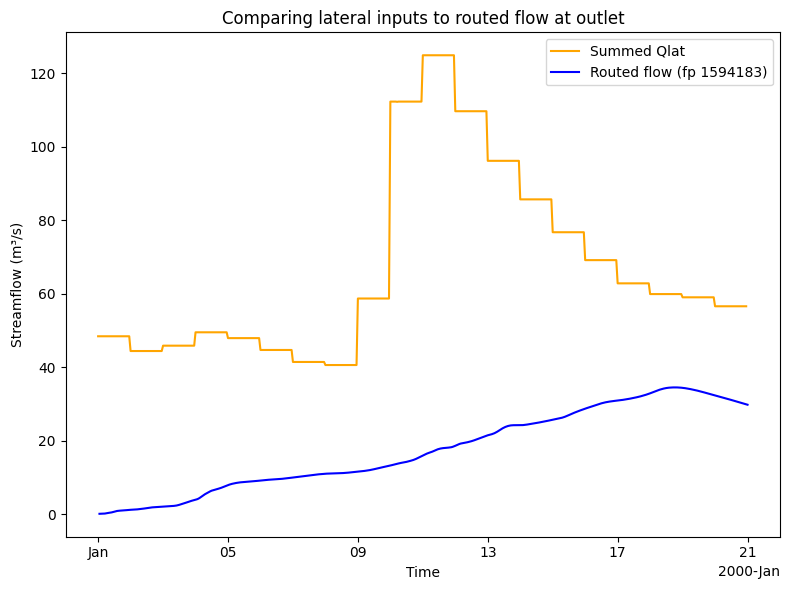

In [8]:
dates = pd.date_range(start="2000-01-01", periods=len(streamflow), freq="h")

fig, ax = plt.subplots(1, 1, figsize=(8,6), sharex=True)

ax.plot(dates, streamflow, label="Summed Qlat", color="orange")
ds.sel(feature_id=outlet_fp_id).flow.plot(ax=ax, label=f'Routed flow (fp {outlet_fp_id})', color="blue")
ax.set_ylabel("Streamflow (m³/s)")
ax.set_xlabel('Time')
ax.set_title("Comparing lateral inputs to routed flow at outlet")
ax.legend()
plt.tight_layout()
plt.show()

If we look above, after the 7 day warmup for T-Route, the model reaches the baseflow of 40 m3/s and correctly responds to the surge in streamflow during the January 14th storm event. The lagging-nature of the hydrograph indicates routing is working! 

Now, let's create a large GIF showing how routing looks across the full domain. The GIF output is already saved to this folder as `flow_animation.gif`

In [9]:
# Animation shows both physical flowpath routed discharge and VFP flow-scaled data
# Physical flowpaths colored by fp_id routed flow, VFPs colored by area-weighted qlat
create_flow_animation(
    ds=ds,
    vfp=vfp,
    divides=divides,
    fp=fp,
    time_step=6,
    save_path="flow_animation.gif",
    fps=12,
)

ValueError: No common feature IDs between dataset and geodataframe

### Flow-Scaling

**All** virtual flowpaths are flow-scaled. Routing operates on discretized links (derived from physical flowpaths), not on VFPs. Each VFP's flow is computed by distributing lateral inflow based on its area contribution:

   `Q_vfp = Q_Lat × (A_vfp / A_Divide)`
   
   where:
   - `Q_Lat` = Lateral flow for the whole divide (output of NGEN)
   - `A_vfp` = Contributing area of the virtual flowpath
   - `A_Divide` = Total contributing area for the divide

This area-weighted distribution is applied to every VFP, regardless of position within the divide.

Using the `visualize_flow_scaling_concept`, we can enter a `div_id` from the subset and look at the flow for the virtual flowpaths contained within the divide. Below is an example divide, but any divide from `divides["div_id"]` can be used!

In [9]:
divides["div_id"]

0       1594183
1       1594204
2       1594205
3       1594228
4       1594229
         ...   
1421    1596134
1422    1596135
1423    1596136
1424    1596137
1425    1596138
Name: div_id, Length: 1426, dtype: int64

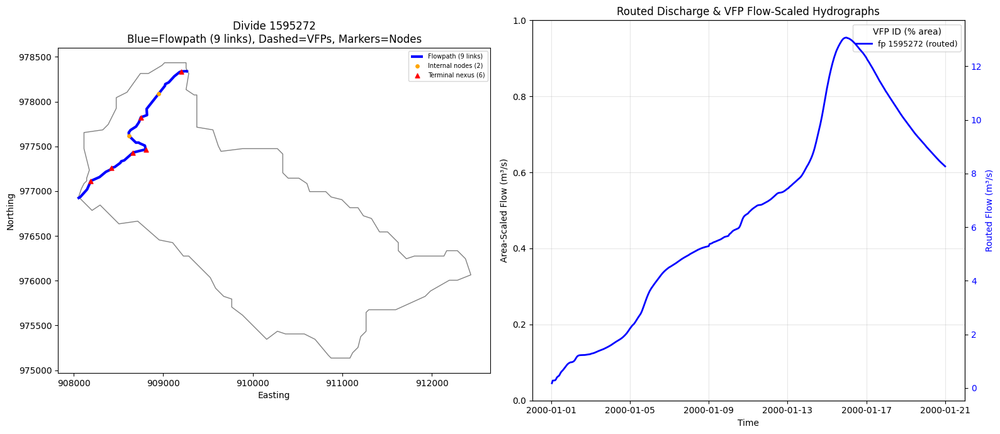

In [10]:
sample_div = 1595272
fig = visualize_links_and_vfps(
    ds=ds,
    fp=fp,
    vfp=vfp,
    ref_fp=ref_fp,
    divides=divides,
    links_df=links_df,
    nodes_df=nodes_df,
    vnex=vnex,
    nexus_gdf=nexus,
    sample_div_id=sample_div,
)

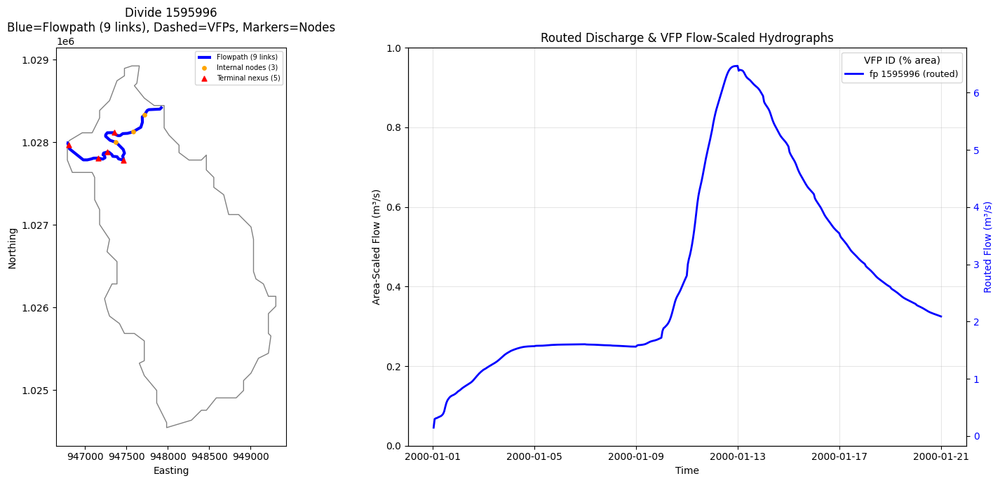

In [11]:
sample_div = 1595996
fig = visualize_links_and_vfps(
    ds=ds,
    fp=fp,
    vfp=vfp,
    ref_fp=ref_fp,
    divides=divides,
    links_df=links_df,
    nodes_df=nodes_df,
    vnex=vnex,
    nexus_gdf=nexus,
    sample_div_id=sample_div,
)

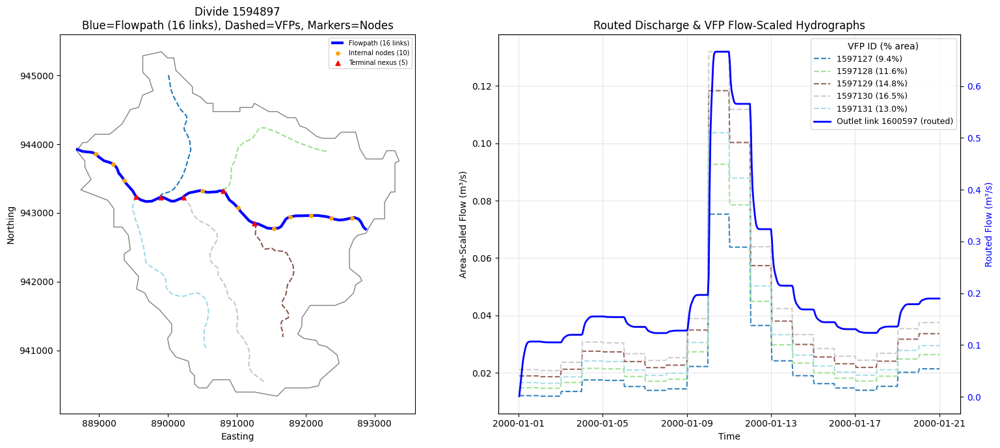

In [10]:
sample_div = 1594897
fig = visualize_links_and_vfps(
    ds=ds,
    fp=fp,
    vfp=vfp,
    ref_fp=ref_fp,
    divides=divides,
    links_df=links_df,
    nodes_df=nodes_df,
    vnex=vnex,
    nexus_gdf=nexus,
    sample_div_id=sample_div,
)

### Conclusions

This notebook demonstrated T-Route's link-based routing on the NHF:

- Physical flowpaths are discretized into ~300m links with terminal virtual nexuses positioned at their real geographic locations
- Muskingum-Cunge routing operates on these links, producing routed flow at link outlets
- Output is reported at the flowpath (`fp_id`) level — each flowpath's Q/V/D comes from its most-downstream (outlet) link
- All virtual flowpaths receive area-weighted flow-scaling output